
=== Starting Bitcoin Causal Analysis ===

Loading data files...
Processing timestamps...
Initial date ranges:
Onchain data: 2009-01-03 00:00:00 to 2024-10-07 00:00:00
Price data: 2020-01-01 00:00:00 to 2024-10-05 00:00:00

Filtered date ranges:
Onchain data: 2020-01-01 00:00:00 to 2024-10-01 00:00:00
Price data: 2020-01-01 00:00:00 to 2024-10-01 00:00:00

Calculating return metrics...

Merging datasets...

Final dataset shape: (1735, 52)
Date range: 2020-01-01 00:00:00 to 2024-10-01 00:00:00
Starting feature preparation...
Creating derived features...
Creating lagged features...
Applying standard scaling...
Processed dataset shape: (1319, 80)
Date range: 2021-02-20 00:00:00 to 2024-10-01 00:00:00
Estimating causal effect using basic graph...
Trying method: backdoor.linear_regression
linear_regression
Estimate value: None
Trying method: backdoor.propensity_score_matching
propensity_score_matching
Estimate value: None
Trying method: backdoor.propensity_score_stratification
propensity_sc

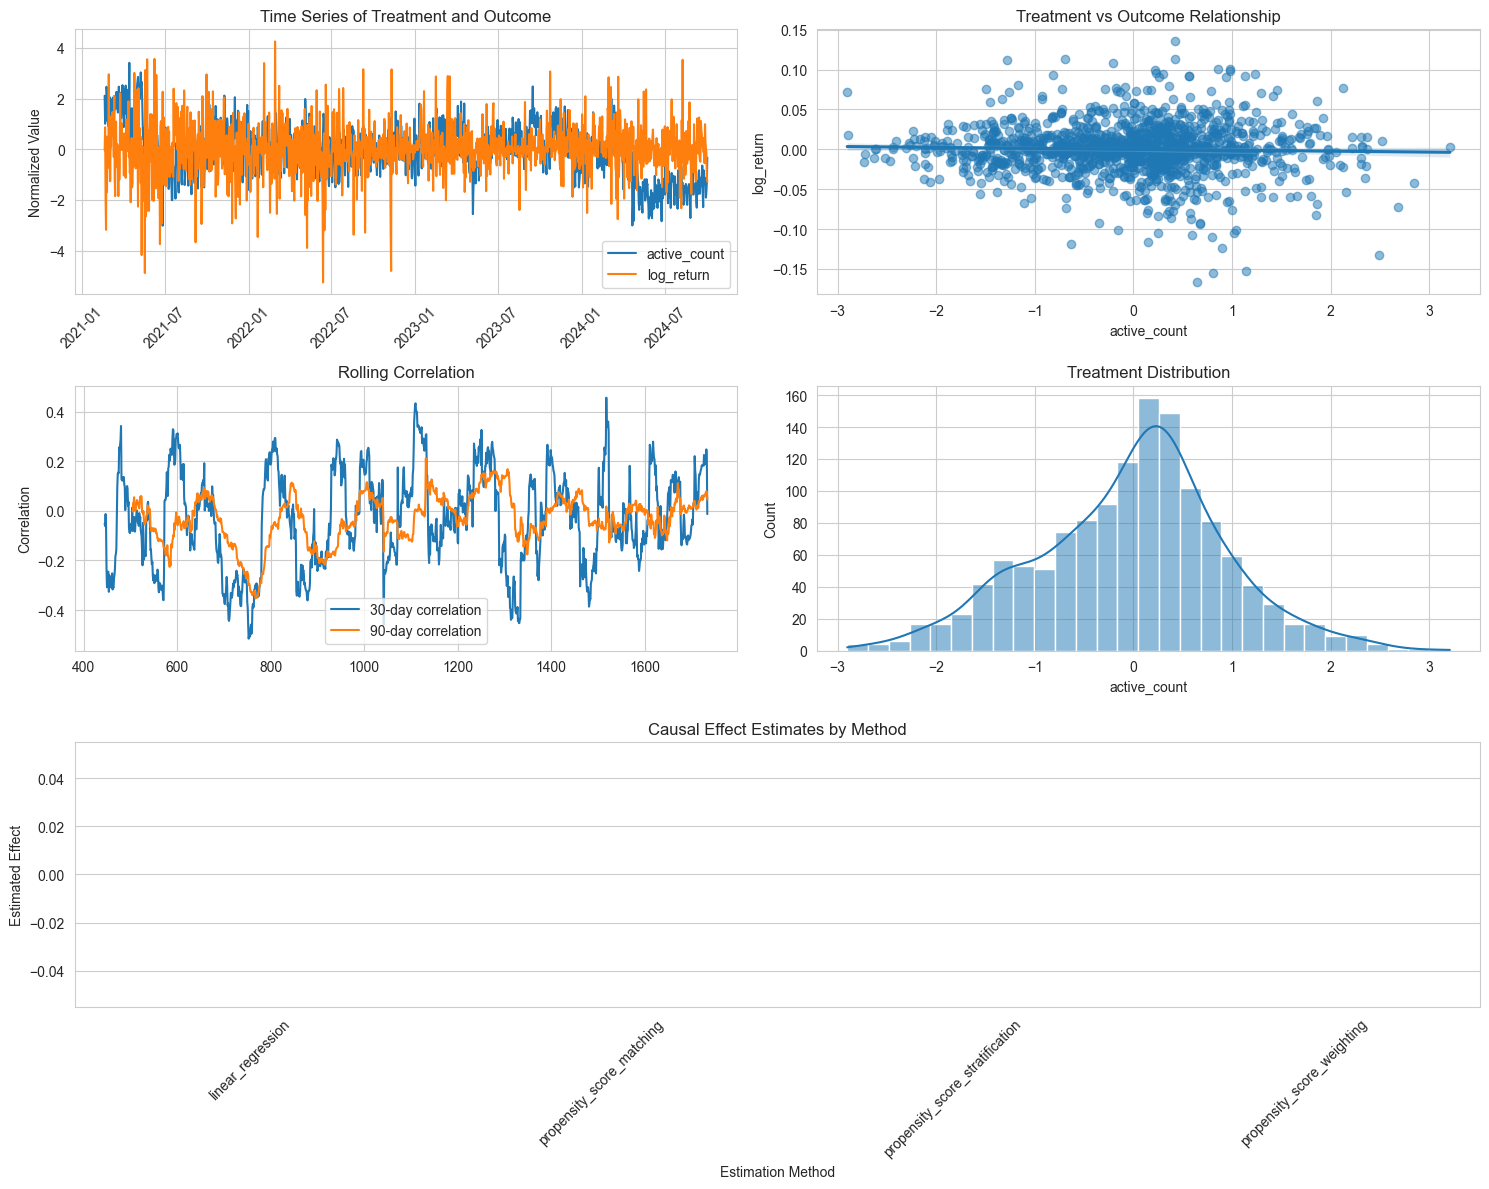


=== Analysis Complete ===

Analysis completed successfully!


In [23]:
import pandas as pd
import numpy as np
from dowhy import CausalModel
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from sklearn.preprocessing import StandardScaler

class BTCCausalAnalysis:
    def __init__(self):
        self.onchain_path = r"C:\Users\eun54\Desktop\FBAQUANT\Capstone Project\glassnode_BTC_tier1_20241008.csv"
        self.price_path = r"C:\Users\eun54\Desktop\FBAQUANT\Capstone Project\BTCUSDT_daily_data_2020_2024.csv"
        self.start_date = pd.to_datetime('2020-01-01')
        self.end_date = pd.to_datetime('2024-10-01')
        self.scaler = StandardScaler()
        
    def load_and_prepare_data(self):
        """Modified data loading with correct time range handling"""
        try:
            print("Loading data files...")
            # Load data
            onchain_df = pd.read_csv(self.onchain_path)
            price_df = pd.read_csv(self.price_path)
            
            print("Processing timestamps...")
            # Convert time columns to datetime
            onchain_df['time'] = pd.to_datetime(onchain_df['time'])
            price_df['open_time'] = pd.to_datetime(price_df['open_time'])
            
            print(f"Initial date ranges:")
            print(f"Onchain data: {onchain_df['time'].min()} to {onchain_df['time'].max()}")
            print(f"Price data: {price_df['open_time'].min()} to {price_df['open_time'].max()}")
            
            # Date filtering with explicit time range
            onchain_df = onchain_df[
                (onchain_df['time'] >= self.start_date) & 
                (onchain_df['time'] <= self.end_date)
            ].copy()
            
            price_df = price_df[
                (price_df['open_time'] >= self.start_date) & 
                (price_df['open_time'] <= self.end_date)
            ].copy()
            
            print("\nFiltered date ranges:")
            print(f"Onchain data: {onchain_df['time'].min()} to {onchain_df['time'].max()}")
            print(f"Price data: {price_df['open_time'].min()} to {price_df['open_time'].max()}")
            
            # Calculate return metrics
            print("\nCalculating return metrics...")
            price_df['log_return'] = np.log(price_df['close']).diff()
            price_df['volatility'] = price_df['log_return'].rolling(window=30, min_periods=1).std()
            price_df['momentum'] = price_df['close'].pct_change(periods=7)
            
            # Merge dataframes
            print("\nMerging datasets...")
            price_df = price_df.rename(columns={'open_time': 'time'})
            merged_df = pd.merge(
                onchain_df,
                price_df[['time', 'log_return', 'volatility', 'momentum', 'close']],
                on='time',
                how='inner'
            )
            
            # Sort by time
            merged_df = merged_df.sort_values('time')
            
            print(f"\nFinal dataset shape: {merged_df.shape}")
            print(f"Date range: {merged_df['time'].min()} to {merged_df['time'].max()}")
            
            return merged_df
            
        except Exception as e:
            print(f"Error in data loading: {str(e)}")
            raise

    def prepare_features(self, df):
        """Modified feature preparation with time series focus"""
        try:
            print("Starting feature preparation...")
            processed_df = df.copy()
            
            # Create additional features
            print("Creating derived features...")
            # Active addresses related features
            processed_df['active_rate'] = processed_df['active_count'] / processed_df['count']
            processed_df['log_active_count'] = np.log1p(processed_df['active_count'])
            processed_df['active_count_ma7'] = processed_df['active_count'].rolling(window=7, min_periods=1).mean()
            processed_df['active_count_ma30'] = processed_df['active_count'].rolling(window=30, min_periods=1).mean()
            
            # Transaction count related features
            processed_df['log_count'] = np.log1p(processed_df['count'])
            processed_df['count_ma7'] = processed_df['count'].rolling(window=7, min_periods=1).mean()
            processed_df['count_ma30'] = processed_df['count'].rolling(window=30, min_periods=1).mean()
            
            # Rate related features
            processed_df['log_rate'] = np.log1p(processed_df['rate'])
            processed_df['rate_ma7'] = processed_df['rate'].rolling(window=7, min_periods=1).mean()
            processed_df['rate_ma30'] = processed_df['rate'].rolling(window=30, min_periods=1).mean()
            
            # Create lagged features
            print("Creating lagged features...")
            lag_periods = [1, 3, 7, 14, 30]
            for col in ['active_count', 'count', 'rate']:
                for lag in lag_periods:
                    processed_df[f'{col}_lag{lag}'] = processed_df[col].shift(lag)
            
            # Create momentum indicators
            processed_df['active_count_momentum'] = processed_df['active_count'].pct_change(periods=7)
            processed_df['count_momentum'] = processed_df['count'].pct_change(periods=7)
            processed_df['rate_momentum'] = processed_df['rate'].pct_change(periods=7)
            
            # Standard scaling for all numeric features except target and time
            print("Applying standard scaling...")
            numeric_cols = processed_df.select_dtypes(include=[np.number]).columns
            target_cols = ['log_return', 'volatility', 'momentum', 'time', 'close']
            scale_cols = [col for col in numeric_cols if col not in target_cols]
            
            processed_df[scale_cols] = self.scaler.fit_transform(processed_df[scale_cols])
            
            # Drop rows with NaN values
            processed_df = processed_df.dropna()
            
            print(f"Processed dataset shape: {processed_df.shape}")
            print(f"Date range: {processed_df['time'].min()} to {processed_df['time'].max()}")
            
            return processed_df
            
        except Exception as e:
            print(f"Error in feature preparation: {str(e)}")
            raise

    def create_causal_graphs(self):
        """Modified causal graphs with time series focus"""
        graphs = {
            'basic': """digraph {
                active_count [label="Active Addresses"];
                log_return [label="BTC Log Return"];
                U [label="Unobserved Confounders"];
                
                active_count -> log_return;
                U -> active_count;
                U -> log_return;
            }""",
            
            'complex': """digraph {
                active_count [label="Active Addresses"];
                log_return [label="BTC Log Return"];
                volatility [label="Volatility"];
                momentum [label="Price Momentum"];
                active_momentum [label="Activity Momentum"];
                U [label="Unobserved Confounders"];
                
                active_count -> log_return;
                active_count -> active_momentum;
                active_momentum -> log_return;
                volatility -> log_return;
                momentum -> log_return;
                U -> active_count;
                U -> log_return;
                U -> volatility;
                U -> momentum;
            }"""
        }
        return graphs

    def estimate_causal_effect(self, df, graph_type='basic', treatment='active_count', outcome='log_return'):
        """Modified causal effect estimation with time series considerations"""
        try:
            print(f"Estimating causal effect using {graph_type} graph...")
            
            # Select relevant columns for the model
            feature_cols = [
                treatment, outcome, 'active_rate', 'log_active_count',
                'active_count_ma7', 'active_count_ma30',
                'count_ma7', 'count_ma30',
                'rate_ma7', 'rate_ma30',
                'volatility', 'momentum'
            ]
            
            df_model = df[feature_cols].copy()
            
            model = CausalModel(
                data=df_model,
                graph=self.create_causal_graphs()[graph_type],
                treatment=treatment,
                outcome=outcome
            )
            
            identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
            
            results = {}
            estimation_methods = [
                ("backdoor.linear_regression", {
                    "fit_intercept": True
                }),
                ("backdoor.propensity_score_matching", {
                    "matcher_class": "NearestNeighbor",
                    "n_neighbors": 3
                }),
                ("backdoor.propensity_score_stratification", {
                    "num_strata": 5
                }),
                ("backdoor.propensity_score_weighting", {
                    "weighting_scheme": "ips_normalized"
                })
            ]
            
            for method, kwargs in estimation_methods:
                try:
                    print(f"Trying method: {method}")
                    estimate = model.estimate_effect(
                        identified_estimand,
                        method_name=method,
                        method_params=kwargs,
                        test_significance=True
                    )
                    
                    if estimate and hasattr(estimate, 'value'):
                        print(f"Estimate value: {estimate.value}")
                        results[method] = {
                            'estimate': estimate,
                            'value': estimate.value,
                            'confidence_intervals': estimate.confidence_intervals if hasattr(estimate, 'confidence_intervals') else None
                        }
                except Exception as method_error:
                    print(f"Method {method} failed: {str(method_error)}")
                    continue
            
            return results if results else None
            
        except Exception as e:
            print(f"Error in causal effect estimation: {str(e)}")
            return None

    def visualize_results(self, df, results, treatment='active_count', outcome='log_return'):
        """Modified visualization with time series focus"""
        try:
            print("Generating visualizations...")
            
            sns.set_style("whitegrid")
            plt.rcParams['figure.figsize'] = [15, 12]
            
            fig = plt.figure()
            
            # Plot 1: Time series of treatment and outcome
            ax1 = plt.subplot(3, 2, 1)
            df_plot = df.copy()
            df_plot[treatment] = (df_plot[treatment] - df_plot[treatment].mean()) / df_plot[treatment].std()
            df_plot[outcome] = (df_plot[outcome] - df_plot[outcome].mean()) / df_plot[outcome].std()
            
            sns.lineplot(data=df_plot, x='time', y=treatment, label=treatment, ax=ax1)
            sns.lineplot(data=df_plot, x='time', y=outcome, label=outcome, ax=ax1)
            ax1.set_xlabel('')
            ax1.set_ylabel('Normalized Value')
            ax1.set_title('Time Series of Treatment and Outcome')
            plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45)
            
            # Plot 2: Scatter plot with regression line
            ax2 = plt.subplot(3, 2, 2)
            sns.regplot(data=df, x=treatment, y=outcome, ax=ax2, scatter_kws={'alpha':0.5})
            ax2.set_xlabel(treatment)
            ax2.set_ylabel(outcome)
            ax2.set_title('Treatment vs Outcome Relationship')
            
            # Plot 3: Rolling correlation
            ax3 = plt.subplot(3, 2, 3)
            windows = [30, 90]
            for window in windows:
                rolling_corr = df[treatment].rolling(window=window).corr(df[outcome])
                sns.lineplot(data=rolling_corr, label=f'{window}-day correlation', ax=ax3)
            ax3.set_xlabel('')
            ax3.set_ylabel('Correlation')
            ax3.set_title('Rolling Correlation')
            
            # Plot 4: Treatment distribution
            ax4 = plt.subplot(3, 2, 4)
            sns.histplot(data=df, x=treatment, kde=True, ax=ax4)
            ax4.set_title('Treatment Distribution')
            
            # Plot 5: Effect estimates comparison
            ax5 = plt.subplot(3, 2, (5, 6))
            if results:
                effect_values = []
                confidence_intervals = []
                method_names = []
                
                for method, result in results.items():
                    if 'value' in result:
                        effect_values.append(result['value'])
                        method_names.append(method.split('.')[-1])
                        if result['confidence_intervals'] is not None:
                            confidence_intervals.append(result['confidence_intervals'])
                
                if effect_values:
                    bars = sns.barplot(x=method_names, y=effect_values, ax=ax5)
                    
                    # Add confidence intervals if available
                    if confidence_intervals:
                        for idx, (ci_lower, ci_upper) in enumerate(confidence_intervals):
                            ax5.vlines(x=idx, ymin=ci_lower, ymax=ci_upper, color='black', linestyle='-', lw=2)
                    
                    ax5.set_xlabel('Estimation Method')
                    ax5.set_ylabel('Estimated Effect')
                    ax5.set_title('Causal Effect Estimates by Method')
                    plt.setp(ax5.xaxis.get_majorticklabels(), rotation=45)
            
            plt.tight_layout()
            return plt
            
        except Exception as e:
            print(f"Error in visualization: {str(e)}")
            return None


    def run_analysis(self):
        """Modified main analysis pipeline with better error handling"""
        try:
            print("\n=== Starting Bitcoin Causal Analysis ===\n")
            
            raw_df = self.load_and_prepare_data()
            if raw_df is None:
                raise ValueError("Failed to load and prepare data")
                
            processed_df = self.prepare_features(raw_df)
            if processed_df is None:
                raise ValueError("Failed to process features")
                
            results = self.estimate_causal_effect(processed_df)
            if results is None:
                print("Warning: No valid causal effects estimated")
            
            plot = self.visualize_results(processed_df, results)
            if plot is not None:
                plot.show()
            
            print("\n=== Analysis Complete ===\n")
            
            return processed_df, results
            
        except Exception as e:
            print(f"\nError in analysis pipeline: {str(e)}")
            return None, None

# 실행
if __name__ == "__main__":
    analyzer = BTCCausalAnalysis()
    try:
        processed_df, results = analyzer.run_analysis()
        if processed_df is not None and results is not None:
            print("Analysis completed successfully!")
        else:
            print("Analysis failed to complete.")
    except Exception as e:
        print(f"Analysis failed with error: {str(e)}")